Homework 2, problem 4, part d

In [4]:
import matplotlib.pyplot as plt
import numpy as np

In [7]:
mean = 10
tau = 20
dt = 0.01
T = 20000
burn = 2000

v_tau_vals = [2, 20, 200]

nu*tau=2: mean=10.26, variance=26.18, skewness=0.658


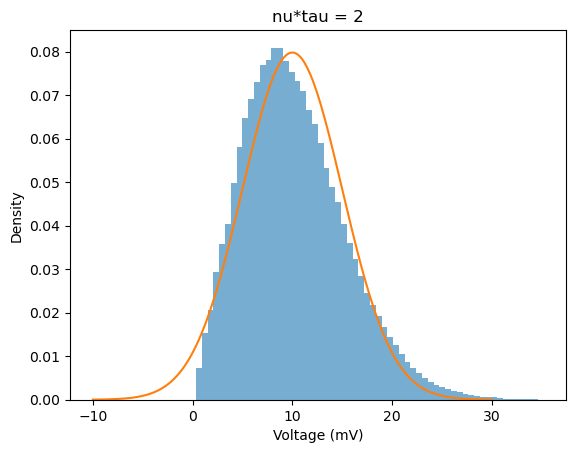

nu*tau=20: mean=10.02, variance=2.50, skewness=0.235
nu*tau=200: mean=9.99, variance=0.26, skewness=0.025


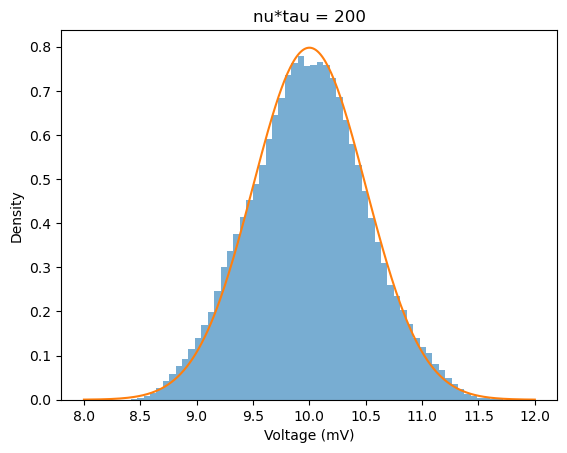

In [10]:
for v_tau in v_tau_vals:
    v = v_tau / tau
    w = mean / v_tau
    
    V = 0
    Vs = []
    
    for t in np.arange(0, T, dt):
        V *= np.exp(-dt / tau)
        V += w * np.random.poisson(v * dt)
        
        if t > burn:
            Vs.append(V)
            
    Vs = np.array(Vs)
    
    # practical
    V_mean = np.mean(Vs)
    V_var = np.var(Vs)
    skewness = np.mean((Vs - V_mean)**3) / np.std(Vs)**3
    
    # theoretical
    var_t = v_tau * w ** 2 / 2
    skew_t = 2 * np.sqrt(2) / (3 * np.sqrt(v_tau))
    
    print(
        f"nu*tau = {v_tau}: "
        f"mean = {V_mean:.2f}, "
        f"variance = {V_var:.2f}, "
        f"skewness = {skewness:.3f}"
    )
    
    # histogram
    if v_tau == 2 or v_tau == 200:
        sigma = np.sqrt(var_t)

        plt.figure()
        plt.hist(Vs, bins=60, density=True, alpha=0.6)

        x = np.linspace(mean - 4*sigma, mean + 4*sigma, 300)
        gaussian = (np.exp(-(x - mean)**2 / (2 * sigma ** 2)) / (np.sqrt(2 * np.pi) * sigma))

        plt.plot(x, gaussian)
        plt.xlabel("Voltage (mV)")
        plt.ylabel("Density")
        plt.title(f"nu*tau = {v_tau}")
        plt.show()